<a href="https://colab.research.google.com/github/nisaerdemli/imageprocessing/blob/main/haftal%C4%B1k9g%C3%B6rev5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

HSV, YUV, CIE Lab ve HSI çıktıları BMP olarak kaydedildi.


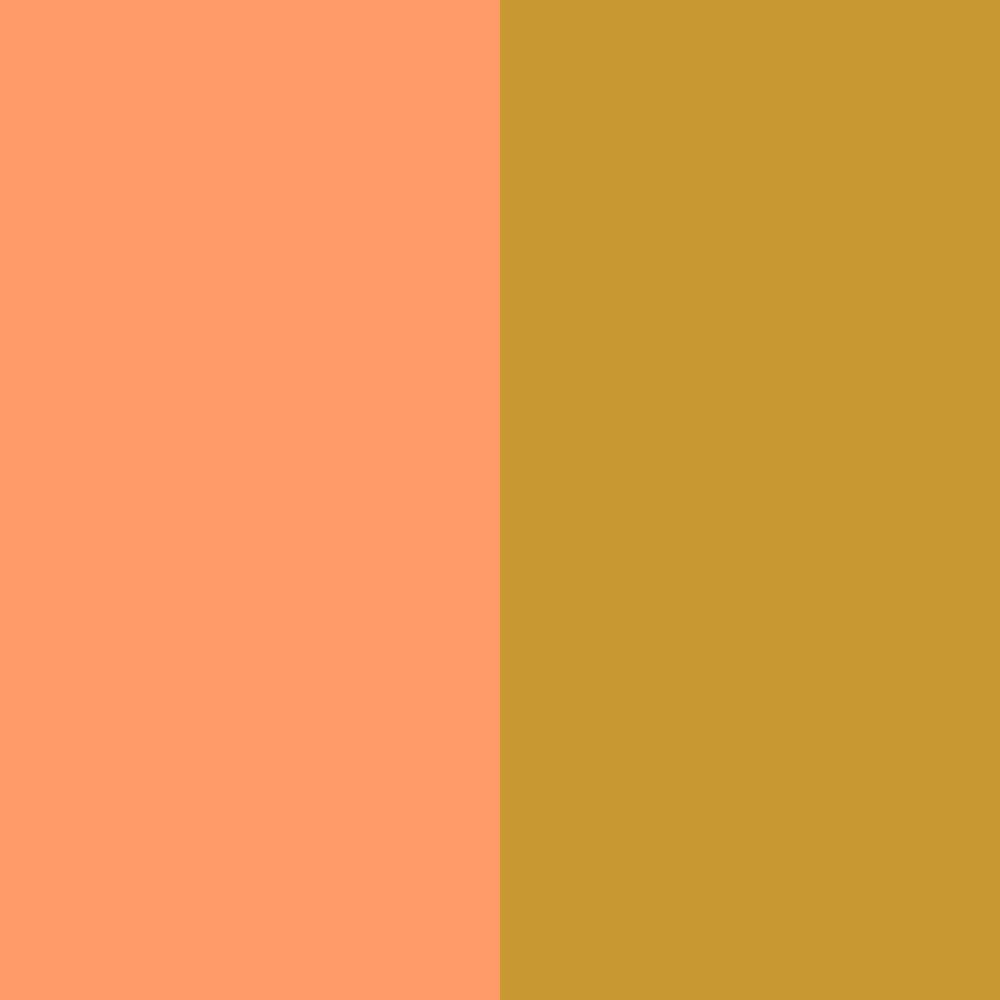

In [1]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

bgr = cv2.imread("renkli_1000.bmp", cv2.IMREAD_COLOR)
if bgr is None:
    bgr = np.zeros((1000, 1000, 3), dtype=np.uint8)
    bgr[:, :500] = (255, 180, 100)
    bgr[:, 500:] = (80, 200, 120)
    cv2.imwrite("renkli_1000.bmp", bgr)

# HSV
hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
cv2.imwrite("cikti_hsv.bmp", hsv)

# YUV
yuv = cv2.cvtColor(bgr, cv2.COLOR_BGR2YUV)
cv2.imwrite("cikti_yuv.bmp", yuv)

# CIE Lab
lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
cv2.imwrite("cikti_lab.bmp", lab)

# HSI
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float64) / 255.0
R, G, B = rgb[:, :, 0], rgb[:, :, 1], rgb[:, :, 2]

I = (R + G + B) / 3.0
min_rgb = np.minimum(np.minimum(R, G), B)
S = np.where(I > 1e-8, 1.0 - (min_rgb / np.maximum(I, 1e-8)), 0.0)

pay = 0.5 * ((R - G) + (R - B))
kok_ici = np.maximum((R - G) ** 2 + (R - B) * (G - B), 0.0)
payda = np.sqrt(kok_ici) + 1e-8
theta = np.arccos(np.clip(pay / payda, -1.0, 1.0))
H = np.where(B <= G, theta, 2.0 * np.pi - theta)
H_deg = np.degrees(H) % 360.0

hsi = np.stack([
    np.clip(H_deg / 360.0 * 255.0, 0, 255),
    np.clip(S * 255.0, 0, 255),
    np.clip(I * 255.0, 0, 255)
], axis=-1).astype(np.uint8)
cv2.imwrite("cikti_hsi.bmp", hsi)

print("HSV, YUV, CIE Lab ve HSI çıktıları BMP olarak kaydedildi.")
cv2_imshow(hsv)